<a href="https://colab.research.google.com/github/melssguzman007/prevencion-fraude-riesgo-crediticio/blob/main/prevencion_fraude_riesgo_crediticio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Prevención de Fraude y Riesgo Crediticio

Proyecto orientado a la detección temprana de fraude en solicitudes de crédito y monitoreo transaccional mediante reglas de negocio en Python (Pandas).

### Objetivos aplicados:
* **Análisis de biometrías de identidad y documentación:** Detección de scores biométricos bajos y documentos apócrifos o adulterados.
* **Detección de patrones inusuales:** Identificación de alta frecuencia de intentos (velocidad), uso de múltiples dispositivos y horarios atípicos.
* **Aplicación de bloqueos preventivos:** Clasificación automática de riesgo para frenar operaciones sospechosas y derivar casos dudosos a revisión manual (KYC).

# Dataset simulado de solicitudes y transacciones

In [10]:
import pandas as pd
import numpy as np


np.random.seed(42)
n_registros = 3000

df = pd.DataFrame({
    'id_solicitud': range(10001, 10001 + n_registros),
    'dni': np.random.randint(20000000, 45000000, size=n_registros),
    'score_biometria': np.round(np.random.normal(loc=88, scale=10, size=n_registros).clip(30, 100), 1),
    'documento_adulterado': np.random.choice([0, 1], size=n_registros, p=[0.96, 0.04]),
    'monto_solicitado': np.round(np.random.lognormal(mean=12.2, sigma=0.6, size=n_registros), 0),
    'intentos_15min': np.random.choice([1, 2, 3, 4, 5, 6], size=n_registros, p=[0.75, 0.14, 0.05, 0.03, 0.02, 0.01]),
    'dispositivos_distintos_24h': np.random.choice([1, 2, 3, 4], size=n_registros, p=[0.85, 0.10, 0.03, 0.02]),
    'hora_solicitud': np.random.randint(0, 24, size=n_registros)
})

duplicados = df.sample(25).copy()
duplicados['id_solicitud'] = range(20001, 20026)
duplicados['dispositivos_distintos_24h'] = 4
duplicados['score_biometria'] = 52.0
df = pd.concat([df, duplicados], ignore_index=True)

print(f"Total de registros cargados: {len(df)}")
df.head()

Total de registros cargados: 3025


,id_solicitud,dni,score_biometria,documento_adulterado,monto_solicitado,intentos_15min,dispositivos_distintos_24h,hora_solicitud
0,10001,43200604,82.2,0,87040.0,1,4,20
1,10002,36094478,75.0,0,101524.0,5,4,20
2,10003,43327850,74.0,0,198825.0,1,1,15
3,10004,41081788,59.9,1,153084.0,2,1,3
4,10005,33315092,94.9,0,95122.0,1,1,22


# Detección de alertas y bloqueos preventivos

In [11]:

df['alerta_identidad'] = np.where(
    (df['score_biometria'] < 70) | (df['documento_adulterado'] == 1), 1, 0
)

umbral_monto = df['monto_solicitado'].quantile(0.95)

df['alerta_patron_inusual'] = np.where(
    (df['intentos_15min'] >= 4) |
    (df['dispositivos_distintos_24h'] >= 3) |
    ((df['monto_solicitado'] > umbral_monto) & (df['hora_solicitud'].between(1, 5))),
    1, 0
)


conteo_dni = df['dni'].value_counts()
dnis_repetidos = conteo_dni[conteo_dni > 1].index
df['alerta_dni_duplicado'] = np.where(df['dni'].isin(dnis_repetidos), 1, 0)


df['total_alertas'] = df['alerta_identidad'] + df['alerta_patron_inusual'] + df['alerta_dni_duplicado']

def clasificar_accion(alertas):
    if alertas >= 2:
        return 'Bloqueo Preventivo'
    elif alertas == 1:
        return 'Revisión Manual (KYC)'
    else:
        return 'Aprobado Automático'

df['accion_preventiva'] = df['total_alertas'].apply(clasificar_accion)

resumen = df['accion_preventiva'].value_counts()
print("--- Resumen de Decisiones del Motor de Prevención ---")
print(resumen)

--- Resumen de Decisiones del Motor de Prevención ---
accion_preventiva
Aprobado Automático      2430
Revisión Manual (KYC)     534
Bloqueo Preventivo         61
Name: count, dtype: int64


# Métricas de impacto y visualización para el reporte

Casos con Bloqueo Preventivo aplicado: 61
Monto total protegido contra posible fraude: $14,955,060


/tmp/ipykernel_18728/169308733.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


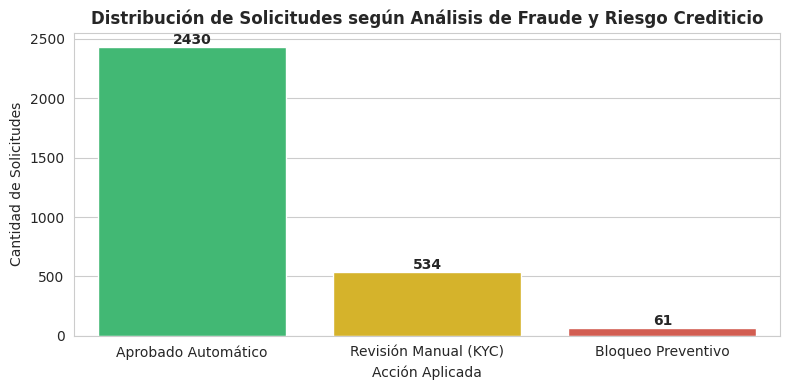

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns


monto_bloqueado = df[df['accion_preventiva'] == 'Bloqueo Preventivo']['monto_solicitado'].sum()
casos_bloqueados = len(df[df['accion_preventiva'] == 'Bloqueo Preventivo'])

print(f"Casos con Bloqueo Preventivo aplicado: {casos_bloqueados}")
print(f"Monto total protegido contra posible fraude: ${monto_bloqueado:,.0f}")


plt.figure(figsize=(8, 4))
sns.set_style("whitegrid")
ax = sns.countplot(
    data=df,
    x='accion_preventiva',
    order=['Aprobado Automático', 'Revisión Manual (KYC)', 'Bloqueo Preventivo'],
    palette=['#2ecc71', '#f1c40f', '#e74c3c']
)
plt.title('Distribución de Solicitudes según Análisis de Fraude y Riesgo Crediticio', fontsize=12, fontweight='bold')
plt.xlabel('Acción Aplicada')
plt.ylabel('Cantidad de Solicitudes')


for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()